# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hammad-vibes/FlyRank-Internship/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

**What this notebook is.** A model score is not a product. This is a small, human-reviewed *action playbook* built on the Week-6 validated model. It is decision-support for a person who decides what to look at first. It is **not** a production system and nothing here acts on its own.

**Plain steps.**
1. Re-create the Week-6 setup: same March 2026 data, same label (`clicks_h2 < 0.8 * clicks_h1`), same five h1 features.
2. Score every page with the **client-grouped out-of-fold** logistic regression from Week 6, so no page is scored by a model that saw its own client.
3. Put each page in an **archetype** and map the archetype to one **action**.
4. Give each page two **reason codes** that say, in plain words, what pushed its risk up.
5. Build a **ranked queue** with a fixed review capacity.

**Archetypes (my assumption).** I did not use clusters. These are simple rules on the validated features, with position tiers taken from the paper (page 1 = positions 1-10, striking distance = 11-20). If I later use the paper's own archetype names, only the table below changes.

| Archetype | Rule (checked in this order) | Action | Lane | Why |
|---|---|---|---|---|
| HIGH_TRAFFIC | h1 clicks in the top 5% | MANUAL_REVIEW_FIRST | 1 human review | Week 6 showed the model is weak exactly here, so a person looks first and the model score does not rank them |
| FLOOR_NOISE | h1 clicks below 8 | WATCH_NEXT_WINDOW | 3 low priority | The label can flip on one or two clicks |
| PAGE_ONE | avg position 10 or better | SNIPPET_AND_FRESHNESS_CHECK | 2 model-ranked | Paper: refine snippets on page-one pages, refresh before decay |
| STRIKING_DISTANCE | avg position 10-20 | RELEVANCE_REFRESH | 2 model-ranked | Paper: pages just outside page 1 are good candidates for a refresh and internal links |
| DEEP | avg position worse than 20 | CHECK_INDEXING_THEN_DECIDE | 3 low priority | Check indexing and overlap before spending refresh effort |

**Ranking rule.** Priority = decline risk x h1 clicks (a rough "clicks exposed" number). HIGH_TRAFFIC pages are ranked by h1 clicks alone, as the model is not trusted for them. The queue has a fixed capacity, a share reserved for the human-review lane, and a cap on how much one client can take (Week 6 showed the flags are concentrated in a few clients).

**Decay / refresh insight (what I can and cannot say).**
- *Paper (observed there):* health peaks at 61-90 days (33.1) and falls to 14 by 271-365 days; 365+ day pages refreshed within 30 days show health 34.5 vs 10.7. That is observational, and my Week-6 question stands: pages that get refreshed may be the ones that were already doing better.
- *My data:* my five features contain **no page age**, so I cannot re-measure the age curve. What I can measure is a two-week change in March: how clicks moved from 1-15 to 16-31 March by archetype and by activity.
- *Practical insight (directional):* a refresh candidate is a **visible** page (8+ clicks) with elevated risk, ranked by how many clicks are exposed. Pages near the 5-click floor tend to fall back after a lucky first half (regression to the mean, not tested here), so a "decline" there is weak evidence of decay.

In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import json, math, zipfile
from pathlib import Path
import duckdb, numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from google.colab import userdata

con = duckdb.connect()
con.execute(f"CREATE SECRET (TYPE huggingface, TOKEN '{userdata.get('HF_TOKEN')}')")
MAR = "hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/month=2026-03/data_0.parquet"
con.execute(f"CREATE VIEW mar AS SELECT * FROM read_parquet('{MAR}')")

frame = con.sql("""
SELECT client_hash_id, content_hash_id,
  SUM(gsc_impressions)  FILTER (WHERE report_date <= DATE '2026-03-15') AS impressions_h1,
  SUM(gsc_clicks)       FILTER (WHERE report_date <= DATE '2026-03-15') AS clicks_h1,
  AVG(gsc_avg_position) FILTER (WHERE report_date <= DATE '2026-03-15') AS avg_position_h1,
  COUNT(*) FILTER (WHERE report_date <= DATE '2026-03-15' AND gsc_impressions > 0) AS active_days_h1,
  SUM(gsc_clicks)       FILTER (WHERE report_date >  DATE '2026-03-15') AS clicks_h2
FROM mar
WHERE gsc_data_available IS TRUE
GROUP BY 1, 2
""").df()

df = frame.copy()
df["h2_missing"] = df["clicks_h2"].isna()
df["clicks_h2"] = df["clicks_h2"].fillna(0)
df["ctr_h1"] = df["clicks_h1"] / df["impressions_h1"].replace(0, np.nan)
FEATURES = ["impressions_h1", "clicks_h1", "ctr_h1", "avg_position_h1", "active_days_h1"]
df = df[df["clicks_h1"] >= 5].dropna(subset=FEATURES).copy()
df["label"] = (df["clicks_h2"] < 0.8 * df["clicks_h1"]).astype(int)
df = df.reset_index(drop=True)
print("rows:", len(df), "| decline rate:", round(df["label"].mean(), 3))


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

rows: 17431 | decline rate: 0.442


In [6]:
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.metrics import roc_auc_score, average_precision_score

GROUP = "client_hash_id"
y = df["label"].values
groups = df[GROUP].values
X = df[FEATURES]
assert not ({"label", "clicks_h2", "h2_missing"} & set(FEATURES)), "future/label column in FEATURES"

def make_logreg():
    return make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=1000))

# Honest score: client-grouped out-of-fold probability of decline (same folds as Week 6)
group_folds = list(GroupKFold(n_splits=5).split(df, y, groups))
risk = np.zeros(len(df))
for tr, te in group_folds:
    assert set(groups[tr]).isdisjoint(groups[te])
    risk[te] = make_logreg().fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]
df["decline_risk"] = risk

# Reason codes: which feature pushes this page's risk up most (explanation of the model, not a cause)
final = make_logreg().fit(X, y)
Z = final[:-1].transform(X)
contrib = Z * final[-1].coef_[0]
CODE_NAME = {"impressions_h1": "IMPRESSIONS", "clicks_h1": "CLICKS", "ctr_h1": "CTR",
             "avg_position_h1": "POSITION", "active_days_h1": "ACTIVE_DAYS"}
PLAIN = {"impressions_h1": "impressions", "clicks_h1": "clicks", "ctr_h1": "click-through rate",
         "avg_position_h1": "average position number (higher = lower on the page)",
         "active_days_h1": "days with impressions"}
def reason_code(i, j):
    return ("HIGH_" if Z[i, j] > 0 else "LOW_") + CODE_NAME[FEATURES[j]]
order = np.argsort(-contrib, axis=1)
r1, r2 = [], []
for i in range(len(df)):
    picks = [reason_code(i, j) if contrib[i, j] > 0 else "NO_RISK_DRIVER" for j in order[i, :2]]
    r1.append(picks[0]); r2.append(picks[1])
df["reason_1"], df["reason_2"] = r1, r2

glossary = {}
for j, f in enumerate(FEATURES):
    for side, word in [("HIGH_", "high"), ("LOW_", "low")]:
        glossary[side + CODE_NAME[f]] = f"{word} {PLAIN[f]} in 1-15 March compared with other pages (the model reads this as higher decline risk)"
glossary["NO_RISK_DRIVER"] = "no feature pushes this page's risk up"
print("Reason-code glossary:")
for k, v in glossary.items():
    print(f"  {k}: {v}")

Reason-code glossary:
  HIGH_IMPRESSIONS: high impressions in 1-15 March compared with other pages (the model reads this as higher decline risk)
  LOW_IMPRESSIONS: low impressions in 1-15 March compared with other pages (the model reads this as higher decline risk)
  HIGH_CLICKS: high clicks in 1-15 March compared with other pages (the model reads this as higher decline risk)
  LOW_CLICKS: low clicks in 1-15 March compared with other pages (the model reads this as higher decline risk)
  HIGH_CTR: high click-through rate in 1-15 March compared with other pages (the model reads this as higher decline risk)
  LOW_CTR: low click-through rate in 1-15 March compared with other pages (the model reads this as higher decline risk)
  HIGH_POSITION: high average position number (higher = lower on the page) in 1-15 March compared with other pages (the model reads this as higher decline risk)
  LOW_POSITION: low average position number (higher = lower on the page) in 1-15 March compared with other 

In [7]:
# Archetypes and actions (rules in the table above)
HI_CLICKS = df["clicks_h1"].quantile(0.95)
df["archetype"] = np.select(
    [df["clicks_h1"] >= HI_CLICKS, df["clicks_h1"] < 8, df["avg_position_h1"] <= 10, df["avg_position_h1"] <= 20],
    ["HIGH_TRAFFIC", "FLOOR_NOISE", "PAGE_ONE", "STRIKING_DISTANCE"], default="DEEP")

ACTION_MAP = {
    "HIGH_TRAFFIC":      ("MANUAL_REVIEW_FIRST",         "1-human-review"),
    "PAGE_ONE":          ("SNIPPET_AND_FRESHNESS_CHECK", "2-model-ranked"),
    "STRIKING_DISTANCE": ("RELEVANCE_REFRESH",           "2-model-ranked"),
    "DEEP":              ("CHECK_INDEXING_THEN_DECIDE",  "3-low-priority"),
    "FLOOR_NOISE":       ("WATCH_NEXT_WINDOW",           "3-low-priority"),
}
df["action"] = df["archetype"].map(lambda a: ACTION_MAP[a][0])
df["lane"] = df["archetype"].map(lambda a: ACTION_MAP[a][1])
df["priority"] = np.where(df["archetype"] == "HIGH_TRAFFIC", df["clicks_h1"], df["decline_risk"] * df["clicks_h1"])
print("HIGH_TRAFFIC threshold (95th percentile of h1 clicks):", round(HI_CLICKS, 1))

# What the data shows per archetype (measured in March 2026)
df["change_ratio"] = df["clicks_h2"] / df["clicks_h1"]
arch = df.groupby("archetype").agg(
    pages=("label", "size"), decline_rate=("label", "mean"), mean_risk=("decline_risk", "mean"),
    median_clicks_h1=("clicks_h1", "median"), median_change_ratio=("change_ratio", "median"))
arch["share_of_pages"] = arch["pages"] / len(df)
arch = arch.loc[["HIGH_TRAFFIC", "PAGE_ONE", "STRIKING_DISTANCE", "DEEP", "FLOOR_NOISE"]]
display(arch.round(3))

# Decay view: two-week change by activity (median clicks_h2 / clicks_h1)
act_band = pd.cut(df["active_days_h1"], [0, 7, 12, 15], labels=["1-7 days", "8-12 days", "13-15 days"])
display(df.groupby(act_band, observed=True).agg(pages=("label", "size"), decline_rate=("label", "mean"),
        median_change_ratio=("change_ratio", "median")).round(3))

HIGH_TRAFFIC threshold (95th percentile of h1 clicks): 55.0


,pages,decline_rate,mean_risk,median_clicks_h1,median_change_ratio,share_of_pages
archetype,,,,,,
HIGH_TRAFFIC,893,0.297,0.333,80.0,1.000,0.051
PAGE_ONE,7916,0.427,0.416,14.0,0.889,0.454
STRIKING_DISTANCE,1376,0.451,0.471,15.0,0.867,0.079
DEEP,1362,0.493,0.456,14.0,0.800,0.078
FLOOR_NOISE,5884,0.471,0.481,6.0,0.800,0.338


,pages,decline_rate,median_change_ratio
active_days_h1,,,
1-7 days,336,0.173,1.545
8-12 days,817,0.340,1.000
13-15 days,16278,0.453,0.833


In [8]:
# Ranked queue with a fixed review capacity (assumptions: change them, not the logic)
CAPACITY = 200            # pages a human can review per cycle (placeholder)
LANE1_SHARE = 0.30        # share of capacity reserved for the human-review lane
MAX_CLIENT_SHARE = 0.25   # one client may take at most this share of each lane

def pick(frame, n, cap):
    chosen, counts = [], {}
    for idx, cl in zip(frame.index, frame[GROUP]):
        if counts.get(cl, 0) < cap:
            chosen.append(idx); counts[cl] = counts.get(cl, 0) + 1
        if len(chosen) == n:
            break
    return frame.loc[chosen]

n1 = int(round(CAPACITY * LANE1_SHARE)); n2 = CAPACITY - n1
lane1 = df[df["lane"] == "1-human-review"].sort_values("priority", ascending=False)
lane2 = df[df["lane"] == "2-model-ranked"].sort_values("priority", ascending=False)
queue = pd.concat([pick(lane1, n1, math.ceil(MAX_CLIENT_SHARE * n1)),
                   pick(lane2, n2, math.ceil(MAX_CLIENT_SHARE * n2))])
queue["rank"] = np.arange(1, len(queue) + 1)
print("queue size:", len(queue), "| by action:", queue["action"].value_counts().to_dict())
print("largest single-client share of queue:", round(queue[GROUP].value_counts(normalize=True).iloc[0], 3))

show = ["rank", "archetype", "action", "decline_risk", "clicks_h1", "impressions_h1", "avg_position_h1",
        "active_days_h1", "reason_1", "reason_2"]
display(queue[show].head(10).round(3))      # no ids shown
display(queue[queue["lane"] == "2-model-ranked"][show].head(10).round(3))

queue size: 200 | by action: {'SNIPPET_AND_FRESHNESS_CHECK': 105, 'MANUAL_REVIEW_FIRST': 60, 'RELEVANCE_REFRESH': 35}
largest single-client share of queue: 0.25


,rank,archetype,action,decline_risk,clicks_h1,impressions_h1,avg_position_h1,active_days_h1,reason_1,reason_2
3618,1,HIGH_TRAFFIC,MANUAL_REVIEW_FIRST,0.115,2395.0,161575.0,2.458,13,HIGH_CTR,NO_RISK_DRIVER
14193,2,HIGH_TRAFFIC,MANUAL_REVIEW_FIRST,0.263,1165.0,67177.0,2.924,15,HIGH_ACTIVE_DAYS,HIGH_CTR
13366,3,HIGH_TRAFFIC,MANUAL_REVIEW_FIRST,0.206,968.0,87662.0,4.536,15,HIGH_ACTIVE_DAYS,HIGH_CTR
15812,4,HIGH_TRAFFIC,MANUAL_REVIEW_FIRST,0.212,914.0,67032.0,3.321,15,HIGH_ACTIVE_DAYS,HIGH_CTR
3763,5,HIGH_TRAFFIC,MANUAL_REVIEW_FIRST,0.137,843.0,132811.0,2.442,13,NO_RISK_DRIVER,NO_RISK_DRIVER
5033,6,HIGH_TRAFFIC,MANUAL_REVIEW_FIRST,0.267,515.0,57477.0,2.328,15,HIGH_ACTIVE_DAYS,HIGH_CTR
7139,7,HIGH_TRAFFIC,MANUAL_REVIEW_FIRST,0.233,502.0,51874.0,3.867,15,HIGH_ACTIVE_DAYS,HIGH_CTR
4341,8,HIGH_TRAFFIC,MANUAL_REVIEW_FIRST,0.179,493.0,108663.0,3.041,15,HIGH_ACTIVE_DAYS,NO_RISK_DRIVER
5114,9,HIGH_TRAFFIC,MANUAL_REVIEW_FIRST,0.267,468.0,60296.0,2.502,15,HIGH_ACTIVE_DAYS,HIGH_CTR
13155,10,HIGH_TRAFFIC,MANUAL_REVIEW_FIRST,0.195,465.0,74133.0,3.153,15,HIGH_ACTIVE_DAYS,NO_RISK_DRIVER


,rank,archetype,action,decline_risk,clicks_h1,impressions_h1,avg_position_h1,active_days_h1,reason_1,reason_2
4802,61,PAGE_ONE,SNIPPET_AND_FRESHNESS_CHECK,0.514,52.0,930.0,2.863,15,LOW_IMPRESSIONS,HIGH_CTR
15786,62,STRIKING_DISTANCE,RELEVANCE_REFRESH,0.503,53.0,1903.0,15.698,15,HIGH_POSITION,HIGH_ACTIVE_DAYS
15604,63,STRIKING_DISTANCE,RELEVANCE_REFRESH,0.487,53.0,2546.0,18.878,15,HIGH_POSITION,HIGH_ACTIVE_DAYS
12846,64,STRIKING_DISTANCE,RELEVANCE_REFRESH,0.524,49.0,989.0,15.833,15,LOW_IMPRESSIONS,HIGH_CTR
15556,65,PAGE_ONE,SNIPPET_AND_FRESHNESS_CHECK,0.500,48.0,1387.0,6.637,15,LOW_IMPRESSIONS,HIGH_ACTIVE_DAYS
2398,66,PAGE_ONE,SNIPPET_AND_FRESHNESS_CHECK,0.458,51.0,1902.0,9.893,15,HIGH_ACTIVE_DAYS,HIGH_CTR
12004,67,PAGE_ONE,SNIPPET_AND_FRESHNESS_CHECK,0.449,52.0,2041.0,8.435,15,HIGH_ACTIVE_DAYS,HIGH_CTR
13476,68,PAGE_ONE,SNIPPET_AND_FRESHNESS_CHECK,0.431,54.0,2584.0,8.394,15,HIGH_ACTIVE_DAYS,HIGH_CTR
6890,69,STRIKING_DISTANCE,RELEVANCE_REFRESH,0.439,53.0,4750.0,15.565,15,HIGH_POSITION,HIGH_ACTIVE_DAYS
12656,70,STRIKING_DISTANCE,RELEVANCE_REFRESH,0.427,54.0,6192.0,18.550,15,HIGH_POSITION,HIGH_ACTIVE_DAYS


**How to read the tables above (safe claims only).**
- The archetype table is **measured** in one month. A high decline rate in an archetype is an observed rate, not proof that pages in it are decaying.
- `median_change_ratio` below 1 means the typical page lost clicks from the first to the second half of March. It is a description of this month, not a forecast.
- The queue is a **ranked reading list for a human**. Rank 1 is "look here first", not "this page will decline".
- Reason codes explain what the model reads as risk. They are **not causes**: a LOW_IMPRESSIONS code does not mean low impressions cause a decline.
- Decline rate by archetype: HIGH_TRAFFIC 0.297, PAGE_ONE 0.427, STRIKING_DISTANCE 0.451, FLOOR_NOISE 0.471, DEEP 0.493 (all pages 0.442). I do not know why HIGH_TRAFFIC is lower.
- The activity table is **not** a decay finding: 16,278 of 17,431 pages (93%) have 13-15 active days, so the 1-7 day group (n=336) and 8-12 day group (n=817) are small and I do not read them as a pattern.
- In the model-ranked lane the risk scores sit in a narrow band (about 0.4-0.5), so priority = risk x clicks mostly orders pages by size: the top ranks of that lane are pages with 48-54 clicks, just under the HIGH_TRAFFIC cutoff. In practice the queue is close to a "bigger visible pages first" list, and the model adds little to the order.
- The most frequent reason code is HIGH_ACTIVE_DAYS, which is the pattern I saw in Week 5. It is a description of what the model uses, not a cause.

## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

**Intended use.**
- *Who:* a content strategist or analyst who already reviews pages and wants a short reading list.
- *For what:* deciding which pages to open first when there is only time for a limited number (the capacity above). The output is a list with a plain reason and a suggested first check.
- *When:* once per cycle, after about two weeks of fresh data, followed by a human review (Section 3).

**Not intended for.** Automatic edits, deletions or publishing; promising a client that a page will recover; judging writers or models; any month, client mix or metric other than the one validated here.

**Limits (all measured or observed in Week 6; the cell below reprints them).**
- One month (features 1-15 March 2026, label 16-31 March 2026). No test on another month.
- Under a client-grouped split the model is only slightly better than the baseline (ROC-AUC under 0.6) and its gain is about the size of the fold-to-fold spread. It is **directional**.
- Weak for high-traffic pages, which is why they go to a person first.
- The label is "clicks fell by more than 20%". Pages near the 5-click floor can flip on one or two clicks, and a page with no h2 data would count as declined (only 1 such row in March).
- No page age, no CPC or revenue, no knowledge of what edits were made.

**Cost / value thinking.** The only costs I model are reviewer minutes. The minutes below are **placeholders** to replace with the team's real numbers. The value check is retrospective and rough: among the queued pages, how many clicks were actually lost between the two halves of March, compared with the same number of randomly chosen pages from the same lane? That tells us whether the queue points at pages where clicks were lost. It does **not** say that a refresh would win those clicks back.

In [9]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
base = -df["impressions_h1"].values
fold_auc = [roc_auc_score(y[te], risk[te]) for _, te in group_folds]
cut = np.quantile(risk, 0.90)
metrics = {
    "scope": {"rows": int(len(df)), "clients": int(df[GROUP].nunique()),
              "features_window": "2026-03-01..2026-03-15", "label_window": "2026-03-16..2026-03-31",
              "label": "clicks_h2 < 0.8 * clicks_h1 (rows with clicks_h1 >= 5)"},
    "validation_grouped_by_client": {
        "decline_rate_all_rows": float(y.mean()),
        "roc_auc_logreg": float(roc_auc_score(y, risk)),
        "roc_auc_baseline_low_impressions": float(roc_auc_score(y, base)),
        "fold_std_logreg": float(np.std(fold_auc)),
        "pr_auc_logreg": float(average_precision_score(y, risk)),
        "top10pct_decline_rate": float(y[risk >= cut].mean())},
}
v = metrics["validation_grouped_by_client"]
print("LIMITS (numbers from this run)")
print(f"  rows {metrics['scope']['rows']}, clients {metrics['scope']['clients']}, one month")
print(f"  ROC-AUC logreg {v['roc_auc_logreg']:.3f} vs baseline {v['roc_auc_baseline_low_impressions']:.3f} (fold std {v['fold_std_logreg']:.3f})")
print(f"  top-10% decline rate {v['top10pct_decline_rate']:.3f} vs {v['decline_rate_all_rows']:.3f} for all rows")

# Cost / value (assumptions are placeholders)
MIN_PER_PAGE = {"1-human-review": 20, "2-model-ranked": 10}
queue["lost_clicks_h2"] = np.maximum(queue["clicks_h1"] - queue["clicks_h2"], 0)   # retrospective only
hours = sum(MIN_PER_PAGE[l] * n for l, n in queue["lane"].value_counts().items()) / 60
print(f"\nreview effort for this queue: about {hours:.1f} hours (placeholder minutes: {MIN_PER_PAGE})")

rng = np.random.RandomState(0)
value = {}
for lane_name, pool in [("1-human-review", lane1), ("2-model-ranked", lane2)]:
    q = queue[queue["lane"] == lane_name]
    lost_q = q["lost_clicks_h2"].mean()
    draws = [np.maximum(s["clicks_h1"] - s["clicks_h2"], 0).mean()
             for s in (pool.sample(len(q), random_state=int(rng.randint(1e6))) for _ in range(200))]
    value[lane_name] = {"queued_pages": int(len(q)), "mean_clicks_lost_queue": float(lost_q),
                        "mean_clicks_lost_random_same_lane": float(np.mean(draws)),
                        "declined_share_queue": float(q["label"].mean()),
                        "declined_share_random_same_lane": float(pool["label"].mean())}
    print(f"{lane_name}: mean clicks lost per queued page {lost_q:.1f} vs {np.mean(draws):.1f} for random pages of the same lane | "
          f"share that declined {q['label'].mean():.3f} vs {pool['label'].mean():.3f}")
metrics["cost_value_retrospective"] = {"assumed_minutes_per_page": MIN_PER_PAGE, "review_hours": float(hours),
                                       "capacity": CAPACITY, "lane1_share": LANE1_SHARE,
                                       "max_client_share": MAX_CLIENT_SHARE, "by_lane": value}


LIMITS (numbers from this run)
  rows 17431, clients 29, one month
  ROC-AUC logreg 0.586 vs baseline 0.549 (fold std 0.036)
  top-10% decline rate 0.562 vs 0.442 for all rows

review effort for this queue: about 43.3 hours (placeholder minutes: {'1-human-review': 20, '2-model-ranked': 10})
1-human-review: mean clicks lost per queued page 46.2 vs 14.1 for random pages of the same lane | share that declined 0.317 vs 0.297
2-model-ranked: mean clicks lost per queued page 9.7 vs 3.8 for random pages of the same lane | share that declined 0.421 vs 0.430


**How to read the cost/value numbers (safe claims only).**
- The human-review lane is chosen by traffic size, so it will naturally show large click losses per page. That is **size**, not skill. Do not read it as the model working.
- For the model-ranked lane, compare with random pages from the same lane, and look at **two** numbers. Clicks lost per page also scales with page size, and the queue favours bigger pages by design (priority = risk x clicks), so a higher number there is partly size. The **share that declined** does not depend on size in the same way. If the queue is not clearly above random on both, I say so; if it is, I say it is **directional**: one month, same data the model was validated on.
- Hours are a rough planning number built on placeholder minutes.
- Model-ranked lane: 42.1% of queued pages declined vs 43.0% of random pages from the same lane. I see **no measured advantage** of the queue over random on this check. The higher clicks lost per queued page (9.7 vs 3.8) reflects page size, not the model.
- Human-review lane: 31.7% declined vs 29.7% for random pages of that lane, and 46.2 vs 14.1 clicks lost per page. This lane is chosen by traffic size, so the larger loss is expected and is not evidence about the model.
- Review effort is about 43 hours per cycle under placeholder minutes (20 per human-review page, 10 per other page).
- Safe reading: the queue is a **reading list sorted by visible traffic**. This month gives no evidence that the risk score improves on random inside the model-ranked lane, so a person must decide which pages deserve action.

## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

**Human review rules (a person does all of these before anything is done).**
1. Open the page and its search data. Check the drop is real and not a tracking gap, seasonality, or an already-known change.
2. Check indexing and overlap with other pages of the same client before blaming the content.
3. Read the reason codes as hints, not causes. Decide yourself what the first check should be.
4. For HIGH_TRAFFIC pages the **model score is not used**: a person reviews them in order of traffic.
5. Record a decision for each queued page: `act`, `defer` or `reject`, plus a one-line note. The exported queue has empty columns for this; reject rates feed the monitoring triggers in Section 4.
6. A client should not take more than a quarter of any lane (already applied in the queue).

**What should NOT be automated (no-go list).**
- Publishing, rewriting or deleting content from a score or a reason code.
- Setting noindex, redirects or merging pages.
- Promising a client that a page will recover or that clicks "will" fall.
- Treating reason codes or feature weights as causes.
- Using the queue to judge writers, models or client accounts.
- Scoring a different month, new client mix or new metric without re-validating first.
- Acting on FLOOR_NOISE pages (under 8 clicks) from this score.
- Showing client names, URLs or page-level queries in the paper or any public output.

In [10]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Review gate: every queued page needs a person. Nothing is allowed to run on its own.
queue["review_level"] = np.where(queue["lane"] == "1-human-review", "FULL_REVIEW_NO_SCORE", "STANDARD_REVIEW")
queue["automation_allowed"] = False
queue["reviewer_decision"] = ""      # act / defer / reject (filled by a person)
queue["reviewer_note"] = ""

assert (queue["automation_allowed"] == False).all()
assert not queue["archetype"].isin(["FLOOR_NOISE", "DEEP"]).any(), "low-priority pages must not be in the queue"
print("review levels:", queue["review_level"].value_counts().to_dict())
print("max client share in any lane:",
      round(queue.groupby("lane")[GROUP].agg(lambda s: s.value_counts(normalize=True).iloc[0]).max(), 3))

NO_GO = ["auto-publish or rewrite content", "auto noindex / redirect / merge pages",
         "client promises of recovery", "reason codes treated as causes",
         "judging writers, models or client accounts",
         "scoring other months or new metrics without re-validation",
         "acting on FLOOR_NOISE pages from this score",
         "client names, URLs or queries in public outputs"]
print("\nNO-GO list:")
for item in NO_GO:
    print("  -", item)


review levels: {'STANDARD_REVIEW': 140, 'FULL_REVIEW_NO_SCORE': 60}
max client share in any lane: 0.25

NO-GO list:
  - auto-publish or rewrite content
  - auto noindex / redirect / merge pages
  - client promises of recovery
  - reason codes treated as causes
  - judging writers, models or client accounts
  - scoring other months or new metrics without re-validation
  - acting on FLOOR_NOISE pages from this score
  - client names, URLs or queries in public outputs


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

**What would tell me the playbook went stale?** Light checks, run each cycle, with **starting thresholds** that are judgement calls and should be revisited after a few cycles.

| Check | What it compares | Trigger (starting value) | Action if triggered |
|---|---|---|---|
| Input drift | Population Stability Index (PSI) of `impressions_h1`, this cycle vs the validated month | PSI above 0.25 | Review the inputs; re-validate before trusting the queue |
| Score drift | PSI of the risk score | PSI above 0.25 | Same |
| Base-rate shift | Share of pages that declined | Moves by more than 10 points from 0.44 | Re-check the label definition and re-validate |
| Skill check | Grouped ROC-AUC on the new window's labels vs the baseline | Gain over baseline below 0.01 | Retire or retrain; fall back to a human-only list |
| Concentration | Largest client share of the queue | Above 0.40 | Re-check the client cap |
| Reviewer feedback | Share of reviewed pages marked `reject` | Above 50% | Stop using the queue; review reason codes with the reviewers |

Retraining is a **decision a person takes**, not an automatic job. The cell below demonstrates the checks. Because I only have March, it uses one held-out set of clients as a stand-in for "the next cycle". In real use the comparison is March vs the new window.

In [11]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
def psi(ref, new, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    a = np.histogram(ref, edges)[0] / len(ref)
    b = np.histogram(new, edges)[0] / len(new)
    a, b = np.clip(a, 1e-4, None), np.clip(b, 1e-4, None)
    return float(np.sum((b - a) * np.log(b / a)))

TRIGGERS = {"psi_impressions": 0.25, "psi_score": 0.25, "base_rate_shift": 0.10,
            "min_gain_over_baseline": 0.01, "max_client_share_queue": 0.40, "max_reject_rate": 0.50}

def check_triggers(ref, new, ref_rate, queue_df=None, new_auc=None, new_base_auc=None, reject_rate=None):
    rows = []
    def add(name, value, ok, limit):
        status = "needs data" if value is None else ("ok" if ok(value) else "TRIGGERED")
        rows.append({"check": name, "value": None if value is None else round(float(value), 3),
                     "limit": limit, "status": status})
    add("input drift (PSI impressions_h1)", psi(ref["impressions_h1"], new["impressions_h1"]),
        lambda v: v <= TRIGGERS["psi_impressions"], TRIGGERS["psi_impressions"])
    add("score drift (PSI risk score)", psi(ref["decline_risk"], new["decline_risk"]),
        lambda v: v <= TRIGGERS["psi_score"], TRIGGERS["psi_score"])
    add("base-rate shift (decline rate)", abs(new["label"].mean() - ref_rate),
        lambda v: v <= TRIGGERS["base_rate_shift"], TRIGGERS["base_rate_shift"])
    gain = None if new_auc is None else new_auc - new_base_auc
    add("skill: gain over baseline (ROC-AUC)", gain, lambda v: v >= TRIGGERS["min_gain_over_baseline"],
        TRIGGERS["min_gain_over_baseline"])
    share = None if queue_df is None else queue_df[GROUP].value_counts(normalize=True).iloc[0]
    add("concentration (largest client share of queue)", share, lambda v: v <= TRIGGERS["max_client_share_queue"],
        TRIGGERS["max_client_share_queue"])
    add("reviewer reject rate", reject_rate, lambda v: v <= TRIGGERS["max_reject_rate"], TRIGGERS["max_reject_rate"])
    return pd.DataFrame(rows)

# DEMO: one held-out set of clients stands in for "next cycle" (not a real future month)
tr_idx, te_idx = group_folds[4]
ref, new = df.iloc[tr_idx], df.iloc[te_idx]
demo = check_triggers(ref, new, ref_rate=float(ref["label"].mean()), queue_df=queue,
                      new_auc=roc_auc_score(new["label"], new["decline_risk"]),
                      new_base_auc=roc_auc_score(new["label"], -new["impressions_h1"]))
display(demo)
print("Reviewer reject rate is 'needs data' until people record decisions in the exported queue.")

,check,value,limit,status
0,input drift (PSI impressions_h1),0.104,0.25,ok
1,score drift (PSI risk score),0.317,0.25,TRIGGERED
2,base-rate shift (decline rate),0.018,0.10,ok
3,skill: gain over baseline (ROC-AUC),0.029,0.01,ok
4,concentration (largest client share of queue),0.250,0.40,ok
5,reviewer reject rate,NaN,0.50,needs data


Reviewer reject rate is 'needs data' until people record decisions in the exported queue.


**How to read the demo (safe claims only).** The demo only shows that the checks run and what they look like. A held-out set of clients from the same month is not a future month, so a clean result here is **not** evidence that the playbook will stay valid. A `TRIGGERED` row means "stop and look", not "the model is wrong".On the held-out clients, input drift (PSI 0.104), base-rate shift (0.018) and the skill check (+0.029 ROC-AUC over the baseline) were within their limits, but **score drift was flagged** (PSI 0.317 vs 0.25). Here the "new" data is a different group of clients from the same month, so the flag points to how much clients differ from one another, not to a change over time. It shows the check can fire and that the 0.25 starting value may be sensitive to client mix; I will look at it again once a second month is available.

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

**What gets exported and why.**
- `work/outputs/w07_ranked_queue.csv`: the ranked queue the paper builds on. It stays out of git by design (hashed ids, data file); this notebook regenerates it. Future columns such as `clicks_h2` and `label` are **not** exported, because a real reader of the queue would not know them.
- `work/outputs/w07_playbook_metrics.json`: the receipts for every number in the paper (validation, thresholds, assumptions, glossary, action map). Commit this one.
- `work/figures/*.png`: two figures to reuse. Commit these.

In Colab the notebook writes to the repo folders when it finds a repo, otherwise to `work/` in the Colab session and builds a small zip you can unzip into the repo root and commit.

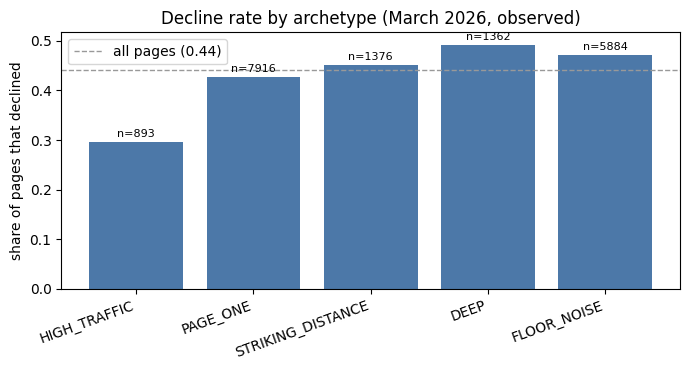

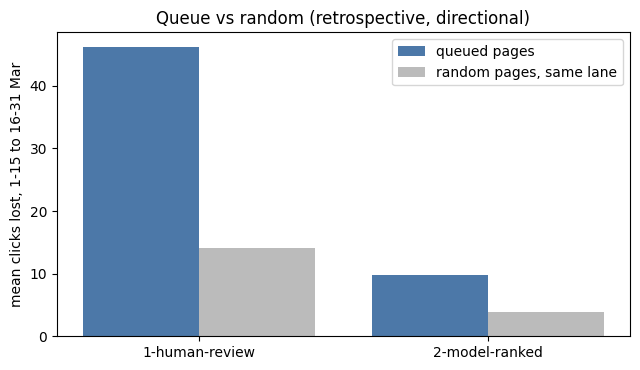

written:
   work/outputs/w07_ranked_queue.csv (45,209 bytes)
   work/outputs/w07_playbook_metrics.json (5,402 bytes)
   work/figures/w07_decline_by_archetype.png (65,120 bytes)
   work/figures/w07_queue_vs_random.png (38,081 bytes)
   w07_exports_to_commit.zip (109,083 bytes)

Commit: work/outputs/w07_playbook_metrics.json and work/figures/*.png (the queue CSV stays out of git).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / ".git").exists() or (q / "work").exists():
            return q
    return p
ROOT = find_root()
OUT, FIG = ROOT / "work" / "outputs", ROOT / "work" / "figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# 1) the queue (no future columns, no names)
QCOLS = ["rank", "content_hash_id", "client_hash_id", "archetype", "action", "lane", "review_level",
         "decline_risk", "priority", "reason_1", "reason_2", "clicks_h1", "impressions_h1",
         "avg_position_h1", "active_days_h1", "automation_allowed", "reviewer_decision", "reviewer_note"]
export_q = queue[QCOLS].copy()
assert not ({"clicks_h2", "label", "lost_clicks_h2", "h2_missing"} & set(export_q.columns))
export_q.to_csv(OUT / "w07_ranked_queue.csv", index=False)

# 2) figures
fig, ax = plt.subplots(figsize=(7, 3.8))
a = arch.copy()
ax.bar(a.index, a["decline_rate"], color="#4C78A8")
ax.axhline(df["label"].mean(), color="#999", ls="--", lw=1, label=f"all pages ({df['label'].mean():.2f})")
for i, (rate, n) in enumerate(zip(a["decline_rate"], a["pages"])):
    ax.text(i, rate + 0.01, f"n={n}", ha="center", fontsize=8)
ax.set_ylabel("share of pages that declined"); ax.set_title("Decline rate by archetype (March 2026, observed)")
ax.legend(); plt.xticks(rotation=20, ha="right"); plt.tight_layout()
fig.savefig(FIG / "w07_decline_by_archetype.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
names, qv, rv = [], [], []
for lane_name, d in metrics["cost_value_retrospective"]["by_lane"].items():
    names.append(lane_name); qv.append(d["mean_clicks_lost_queue"]); rv.append(d["mean_clicks_lost_random_same_lane"])
xx = np.arange(len(names)); ax.bar(xx - 0.2, qv, 0.4, label="queued pages", color="#4C78A8")
ax.bar(xx + 0.2, rv, 0.4, label="random pages, same lane", color="#BBB")
ax.set_xticks(xx); ax.set_xticklabels(names); ax.set_ylabel("mean clicks lost, 1-15 to 16-31 Mar")
ax.set_title("Queue vs random (retrospective, directional)"); ax.legend(); plt.tight_layout()
fig.savefig(FIG / "w07_queue_vs_random.png", dpi=150); plt.show()

# 3) metrics JSON (the receipts)
metrics["archetype_table"] = json.loads(arch.round(4).to_json(orient="index"))
metrics["action_map"] = {k: {"action": v[0], "lane": v[1]} for k, v in ACTION_MAP.items()}
metrics["reason_code_glossary"] = glossary
metrics["high_traffic_threshold_clicks_h1"] = float(HI_CLICKS)
metrics["queue"] = {"size": int(len(queue)), "by_action": queue["action"].value_counts().to_dict(),
                    "largest_client_share": float(queue[GROUP].value_counts(normalize=True).iloc[0])}
metrics["monitoring_triggers_starting_values"] = TRIGGERS
metrics["no_go"] = NO_GO
metrics["claim_language"] = "observed / measured / directional / decision-support; one month; not production"
(OUT / "w07_playbook_metrics.json").write_text(json.dumps(metrics, indent=2))

# 4) zip of what to commit (figures + metrics JSON)
ZIP = ROOT / "w07_exports_to_commit.zip"
with zipfile.ZipFile(ZIP, "w") as z:
    for p in [OUT / "w07_playbook_metrics.json", FIG / "w07_decline_by_archetype.png", FIG / "w07_queue_vs_random.png"]:
        z.write(p, arcname=str(p.relative_to(ROOT)))
print("written:")
for p in [OUT / "w07_ranked_queue.csv", OUT / "w07_playbook_metrics.json",
          FIG / "w07_decline_by_archetype.png", FIG / "w07_queue_vs_random.png", ZIP]:
    print("  ", p.relative_to(ROOT), f"({p.stat().st_size:,} bytes)")
print("\nCommit: work/outputs/w07_playbook_metrics.json and work/figures/*.png (the queue CSV stays out of git).")
try:
    from google.colab import files
    files.download(str(ZIP))
except Exception:
    pass

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.